In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from solvers import GKSIAS
from psolvers import PGKSIAS

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
#A = jlinops.IdentityOperator((n,n))
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

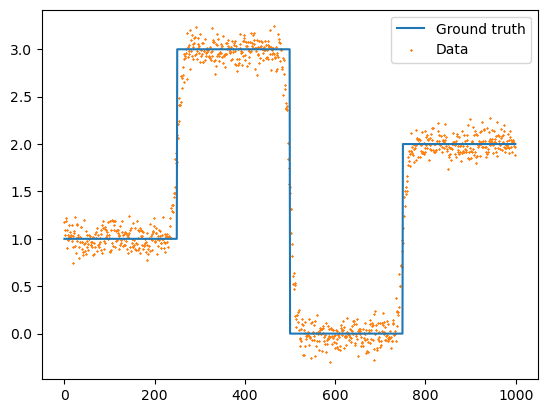

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

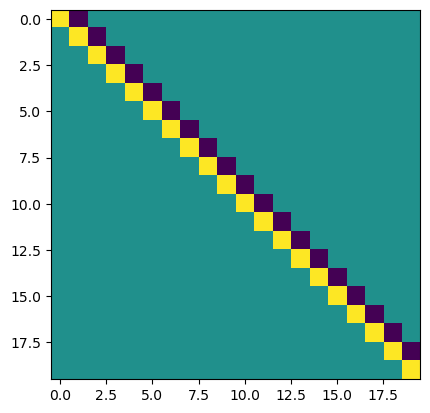

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Set up methods for comparison (first do convex case)

In [6]:
# # Set up priorconditioning pseudoinverse factory (shortcut here since linearly indpendent rows, less of a cheating way below)
# # _Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
# # Lpinv_factory = lambda wr: _Lpinv @ jlinops.DiagonalOperator(1.0/wr)

# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

# W = jlinops.MatrixLinearOperator(Wmat)


# # Whiten the forward operator and observation by the noise covariance (don't actually need to do this when using gcv)
# Atilde = (1.0/noise_stdev)*F
# btilde = (1.0/noise_stdev)*noisy_signal

# # Solve problem with GKSIAS
# gks_sol3, gks_data3 = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
#                            projection_dim=3, n_iter=200, regparam="gcv", x_true=ground_truth, 
#                            #regparam_fixed=1.0/gks_data["vartheta_history"][-1]
#                            )
# #variant="modified", fullsize=btilde.size

In [7]:
# TRIPs-Py methods are dp and gcv. The rest I have added. I believe dp is the same as dp3, except uses the GSVD in the formulation of the method whereas dp3 avoids using a GSVD.
# methods = ["dp", "dp2", "dp3", "mgcv", "gcv", "matlab_gcv", "mgcv_no_whitening", "gcv_no_whitening", "matlab_gcv_no_whitening" ]
#methods = ["dp", "dp2", "dp3", "mgcv", "gcv", "matlab_gcv" ]
methods = ["dp3"]
methods = [1e-1]
print(f"Number of methods to compare: {len(methods)}")

Number of methods to compare: 1


In [8]:
import scipy.sparse as sps

# Set problem parameters
n_iters = 50
hyperpr_r = 1
hyperpr_beta = 1.5 + 1e-3

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Pseudoinverse factory
def Lpinv_factory(wr):
    Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
    return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

# _Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
# Lpinv_factory = lambda wr: _Lpinv @ jlinops.DiagonalOperator(1.0/wr)

W = jlinops.MatrixLinearOperator(Wmat)

Atilde = (1.0/noise_stdev)*A
btilde = (1.0/noise_stdev)*noisy_signal

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    regparam = method
    
    gksias_data = PGKSIAS(Atilde, btilde, L, W=W, Lpinv_factory=Lpinv_factory, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, 
                           projection_dim=10, n_iter=n_iters, regparam=regparam, x_true=ground_truth, 
                           #regparam_fixed=1.0/gks_data["vartheta_history"][-1]
                           )

    # Run the solver
    #data = gksias_solver.solve(n_iter=n_iters, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam)

    # Put results into dict
    comp_dct[method] = gksias_data

Started method: 0.1


TypeError: unsupported operand type(s) for *: 'NoneType' and 'float'

In [10]:
plt.plot(comp_dct[0.1][0])
plt.show()

KeyError: 0.1

# Comparison plots

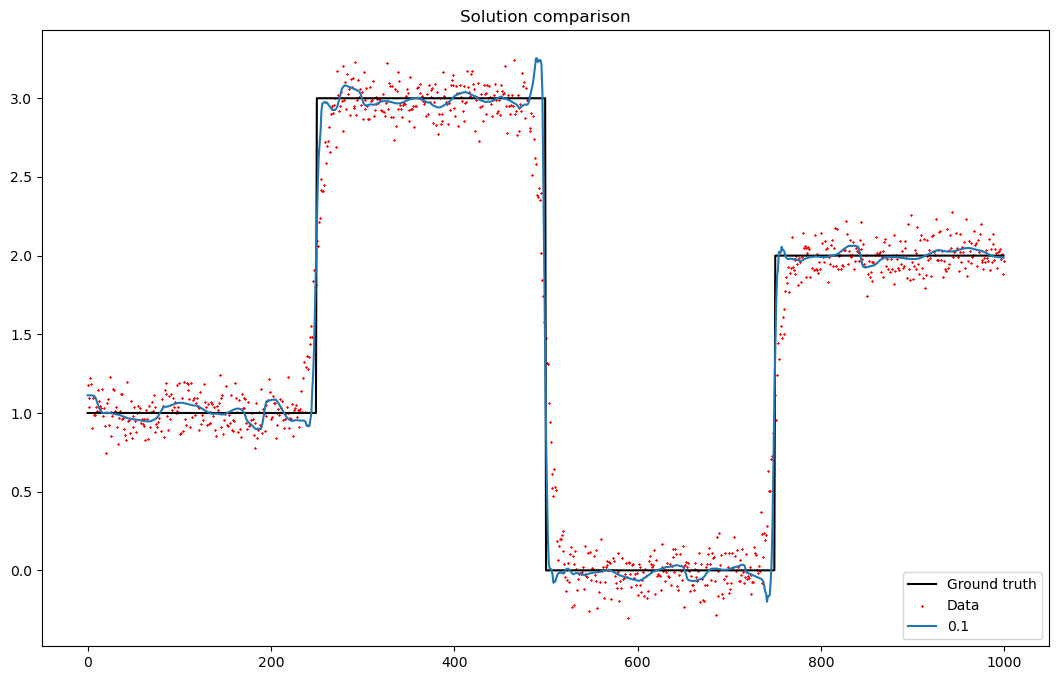

In [25]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.plot(grid, data[0], label=method)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

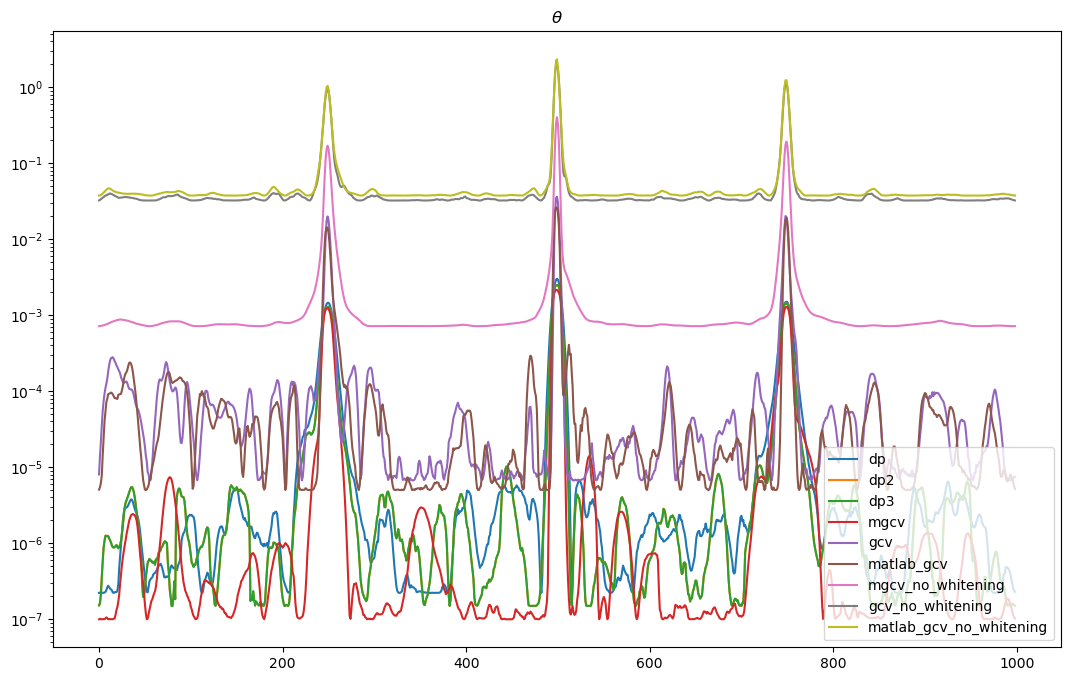

In [10]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(grid[:-1], data["theta"], label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

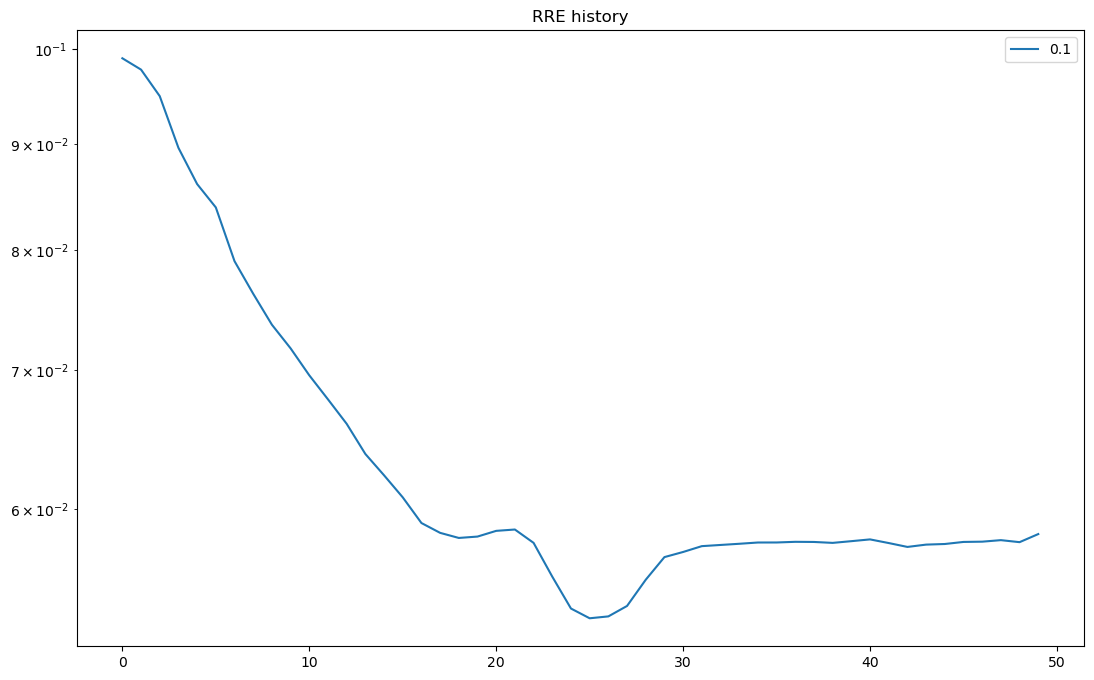

In [27]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data[1]["relError"], label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

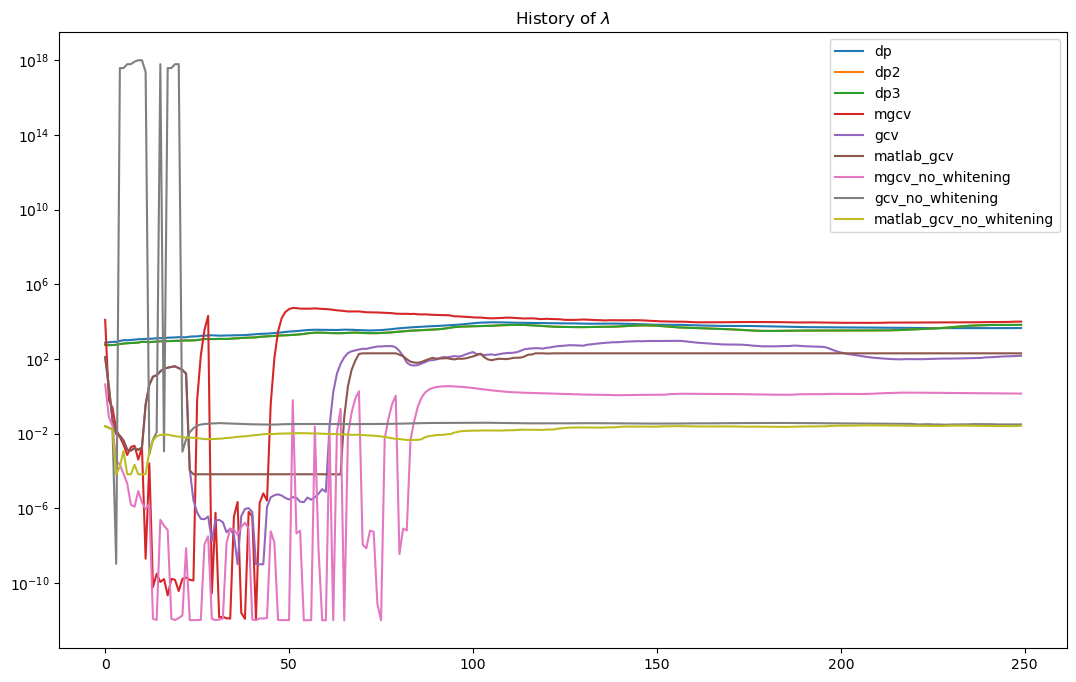

In [14]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    data = comp_dct[method]
    plt.semilogy(data["lambda_history"], label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()

# Also do a nonconvex prior?

In [16]:
# Set problem parameters
n_iters = 150
hyperpr_r = -1
hyperpr_beta = 1.0

# Build a dictionary containg solvers and solver results
comp_dct = {}

# Iterate over methods
for method in methods:
    print(f"Started method: {method}")

    # Build solver
    if (method == "mgcv_no_whitening") or (method == "gcv_no_whitening") or (method == "matlab_gcv_no_whitening"):
        gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=None)
    else:
        gksias_solver = GKSIAS(A, L, noisy_signal, noise_var=noise_var)

    # Processing for regparam method
    if (method == "mgcv_no_whitening"):
        regparam = "mgcv"
    elif (method == "gcv_no_whitening"):
        regparam = "gcv"
    elif (method == "matlab_gcv_no_whitening"):
        regparam = "matlab_gcv"
    else:
        regparam = method

    try:
        # Run the solver
        data = gksias_solver.solve(n_iter=n_iters, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=regparam)
    except:
        print(f"failed for method = {method}")

    # Put results into dict
    comp_dct[method] = data

Started method: dp


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
failed for method = dp
Started method: dp2


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/comparisons/../solvers.py:514: RuntimeWarning: invalid value encountered in sqrt
  y, _ , _, svals = np.linalg.lstsq(np.concatenate((R_A, np.sqrt(lambdah) * R_WL)), np.concatenate((Q_A.T @ self.b, np.zeros((R_WL.shape[0],)))), rcond=None)


Started method: dp3


Started method: mgcv


Started method: gcv


Started method: matlab_gcv


Started method: mgcv_no_whitening


Started method: gcv_no_whitening


Started method: matlab_gcv_no_whitening


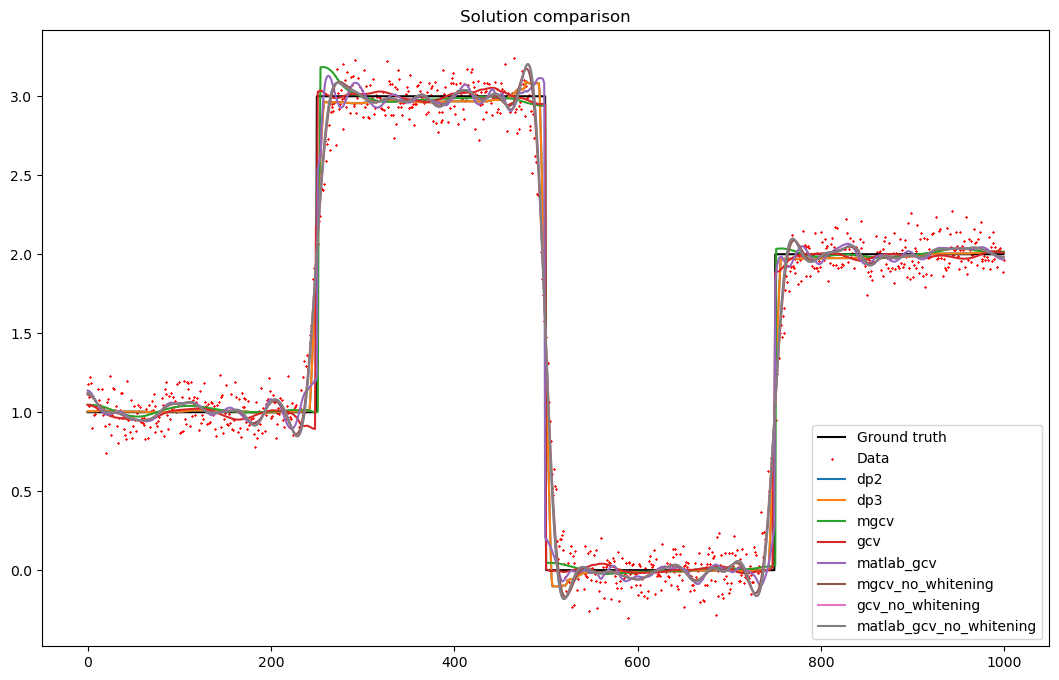

In [24]:
plt.figure(figsize=(13,8))

plt.plot(grid, ground_truth, label="Ground truth", color="black")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="red", alpha=1.0, s=0.5)

for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.plot(grid, data["x"], label=method)

plt.legend(loc="lower right")
plt.title("Solution comparison")
plt.show()

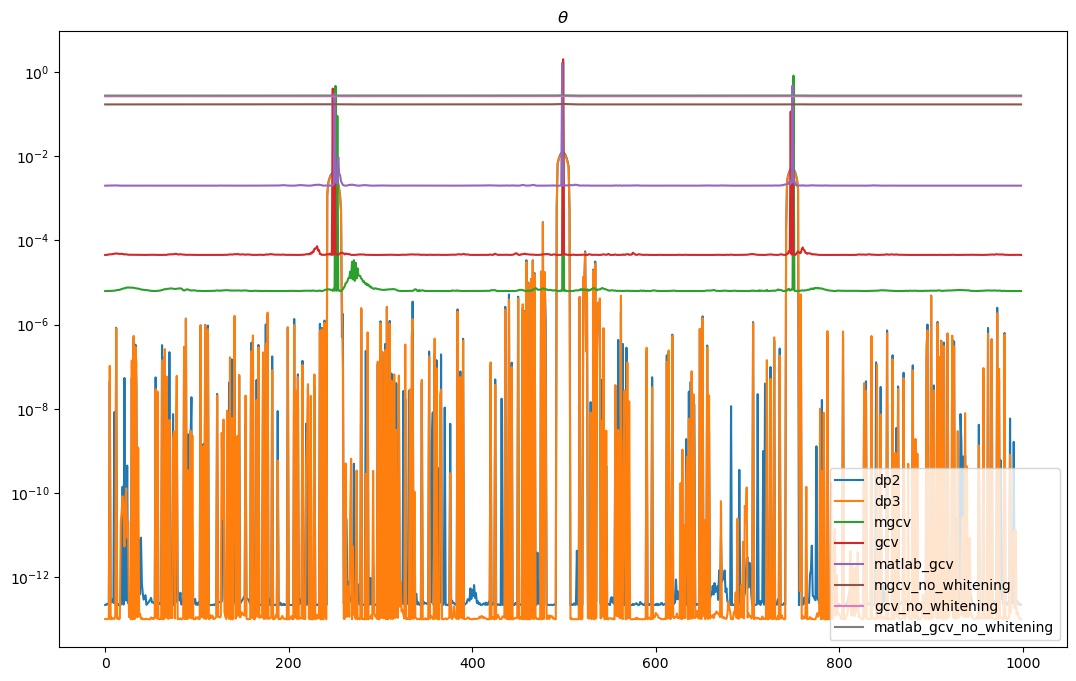

In [23]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.semilogy(grid[:-1], data["theta"], label=method)

plt.legend(loc="lower right")
plt.title("$\\theta$")
plt.show()

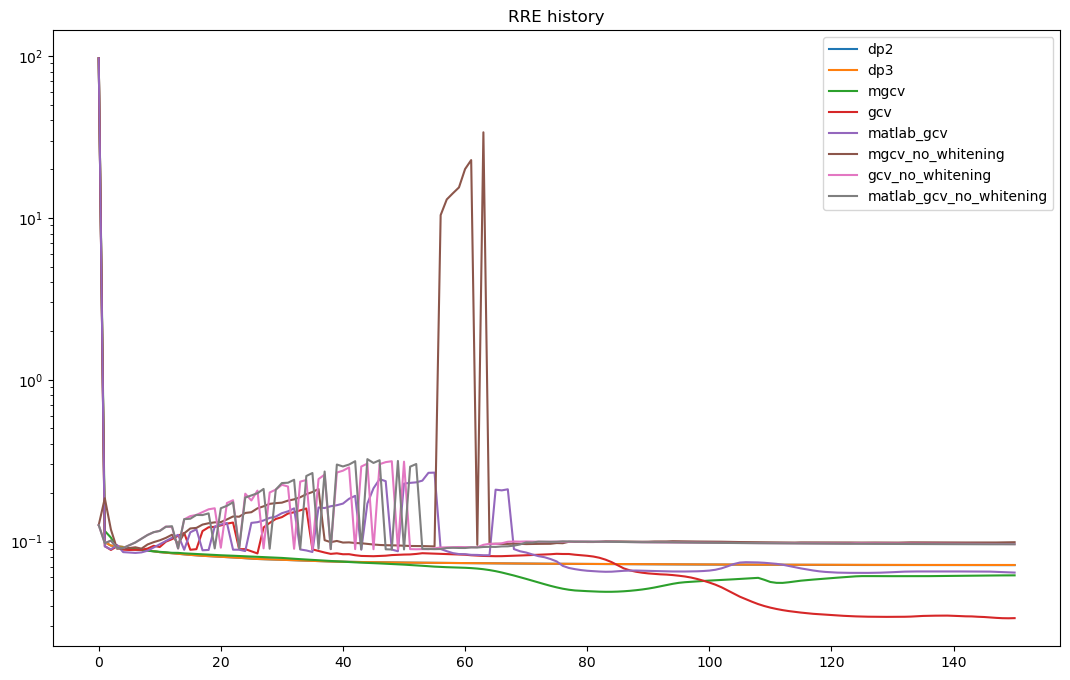

In [21]:
plt.figure(figsize=(13,8))


for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.semilogy(data["rre_history"], label=method)

plt.legend(loc="upper right")
plt.title("RRE history")
plt.show()

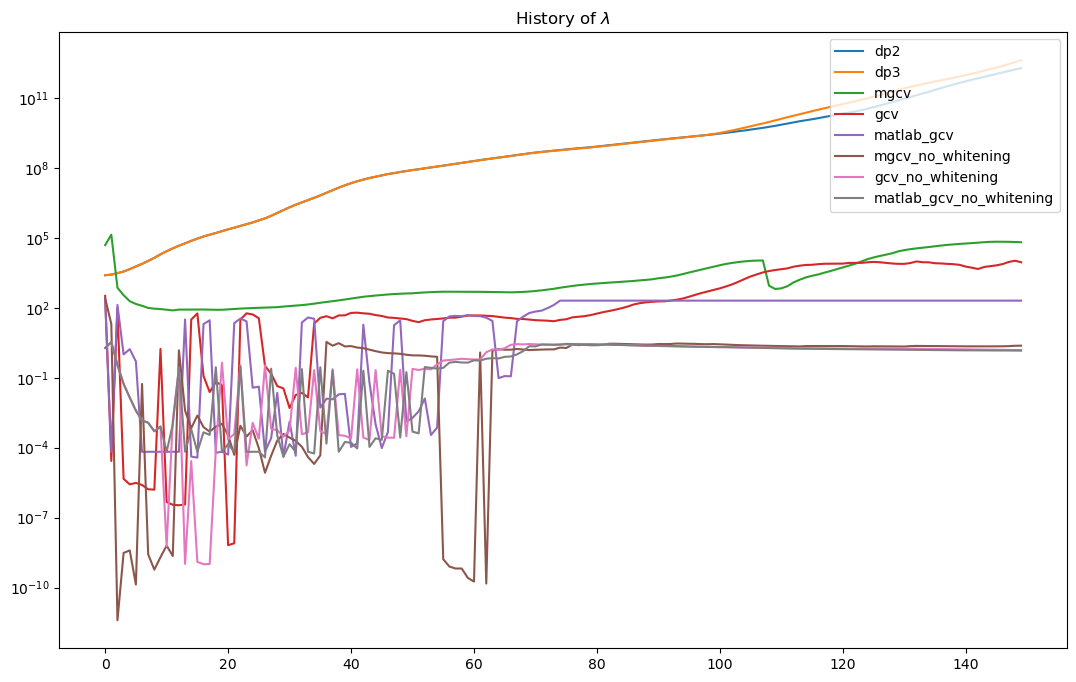

In [22]:
plt.figure(figsize=(13,8))

for method in comp_dct.keys():
    if method == "dp":
        pass
    else:
        data = comp_dct[method]
        plt.semilogy(data["lambda_history"], label=method)

plt.legend(loc="upper right")
plt.title("History of $\\lambda$")
plt.show()